# Lab01 - sprint 1

## Random Variables: Raman Spectral Intensities

## Description

In [ ]:
При повторных измерениях одного и того же состава интенсивности могут различаться из-за погрешности лабораторного 
прибора (спектрофотометра), из за человеческого фактора, так как люди сколонны совершать ошибки в точных измерениях 
(при подготовке пробы, при настройке прибора). При разных измерениях температура в комнате может быть разной, 
образец может быть загрязнен.Так же величина случайна, так как состав раствора разный, это влияет напрямую на 
интенсивность, поэтому мы исследуем как различия между составами, так и вариации между повторами.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

base_url = (
    "https://raw.githubusercontent.com/"
    "Alvaro-FG/Raman_Sugars/main/"
)

spectra = pd.read_csv(
    base_url + "Sugar_Concentration_Test_ALL_spectra.csv"
)

metadata = pd.read_csv(
    base_url + "Sugar_Concentration_Test_ALL_metadata.csv"
)

print("Размер таблицы спектров:", spectra.shape)
print("Размер таблицы метаданных:", metadata.shape)

print("\nСтолбцы метаданных:")
print(metadata.columns.tolist())

print("\nПервые строки метаданных:")
print(metadata.head())

print("\nПервые строки спектров:")
print(spectra.iloc[:5, :5])

Размер таблицы спектров: (2000, 1961)
Размер таблицы метаданных: (1960, 14)

Столбцы метаданных:
['samp', 'row', 'col', 'plate', 'round', 'meas', 'rep', 'filename', 'Sucrose [ul]', 'Fructose [ul]', 'Maltose [ul]', 'Glucose [ul]', 'Water [ul]', 'Total Volume [ul]']

Первые строки метаданных:
   samp row  col  plate  round  meas  rep  \
0    54   E    6      2      2     1    1   
1    43   D    7      3      2     1    2   
2    35   C   11      2      2     1    4   
3    10   A   10      1      1     1    3   
4    94   H   10      1      2     1    1   

                                      filename  Sucrose [ul]  Fructose [ul]  \
0   Sugar_Concentration_Test_54_E6_2_RD2_M1_R1            30             30   
1   Sugar_Concentration_Test_43_D7_3_RD2_M1_R2             0              0   
2  Sugar_Concentration_Test_35_C11_2_RD2_M1_R4            30             75   
3  Sugar_Concentration_Test_10_A10_1_RD1_M1_R3           120            120   
4  Sugar_Concentration_Test_94_H10_1_RD2_M

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Частоты спектра
wavenumbers = spectra["Wavenumber [cm-1]"].to_numpy()

# Ищем ближайшую измеренную частоту к каждой целевой
targets = [500, 1000, 1400]
selected_indices = [
    np.abs(wavenumbers - target).argmin()
    for target in targets
]

for target, idx in zip(targets, selected_indices):
    print(
        f"Целевая частота: {target} см⁻¹; "
        f"фактическая: {wavenumbers[idx]:.2f} см⁻¹"
    )

Целевая частота: 500 см⁻¹; фактическая: 500.33 см⁻¹
Целевая частота: 1000 см⁻¹; фактическая: 998.80 см⁻¹
Целевая частота: 1400 см⁻¹; фактическая: 1399.34 см⁻¹


Получаем интенсивности на трех выбранных частотах (для наглядности мы выводим только 9 строк, на самом же деле их очевидно, что гораздо больше):

In [4]:
X = spectra.iloc[selected_indices, 1:].T.copy()

X.columns = ["X1", "X2", "X3"]
X = X.reset_index(drop=True)

# Добавляем метаданные: состав смеси и номер повторения
data = pd.concat(
    [metadata.reset_index(drop=True), X],
    axis=1
)

print("Размер итоговой таблицы:", data.shape)
print("\nПервые строки:")
print(data[[
    "Sucrose [ul]", "Fructose [ul]",
    "Maltose [ul]", "Glucose [ul]",
    "X1", "X2", "X3"
]].head(9))

print("\nОписательная статистика:")
print(data[["X1", "X2", "X3"]].describe().round(2))

Размер итоговой таблицы: (1960, 17)

Первые строки:
   Sucrose [ul]  Fructose [ul]  Maltose [ul]  Glucose [ul]      X1      X2  \
0            30             30            75           120  3951.0  1693.0   
1             0              0            30            75  3120.0  1452.0   
2            30             75           120            75  3994.0  1760.0   
3           120            120             0             0  3505.0  1657.0   
4            75             30            30             0  2999.0  1456.0   
5             0             30            75            75  3439.0  1586.0   
6            75              0            75           120  4170.0  1799.0   
7             0            120           120           120  4240.0  1775.0   
8            30             75            75             0  3253.0  1568.0   

       X3  
0  1579.0  
1  1225.0  
2  1823.0  
3  1544.0  
4  1349.0  
5  1520.0  
6  1713.0  
7  1784.0  
8  1486.0  

Описательная статистика:
            X1       

## Random Variable 01 (X1 - интенсивность на длине волны 500.33 cm⁻¹)


### EDA, Distribution

#### Визуализация и описательные статистики

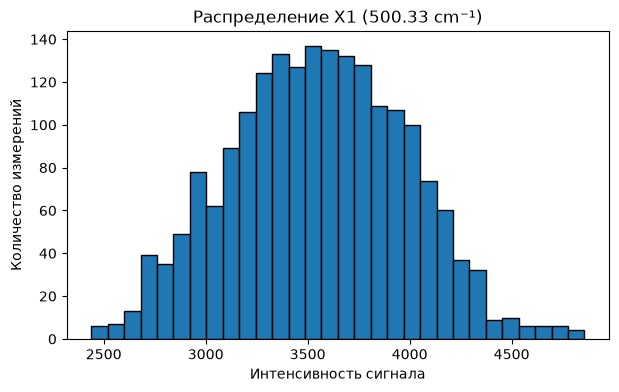

In [11]:
plt.figure(figsize=(7, 4))

plt.hist(data["X1"], bins=30, edgecolor="black")
plt.title("Распределение X1 (500.33 cm⁻¹)")
plt.xlabel("Интенсивность сигнала")
plt.ylabel("Количество измерений")

plt.show()

In [17]:
print("Медиана X1:", data["X1"].median())
print("Мода X1:", data["X1"].mode().tolist())

Медиана X1: 3556.0
Мода X1: [3251.0, 3298.0, 3736.0]


In [14]:
print("Асимметрия X1:", round(data["X1"].skew(), 3))
print("Эксцесс X1:", round(data["X1"].kurt(), 3))

Асимметрия X1: 0.048
Эксцесс X1: -0.353


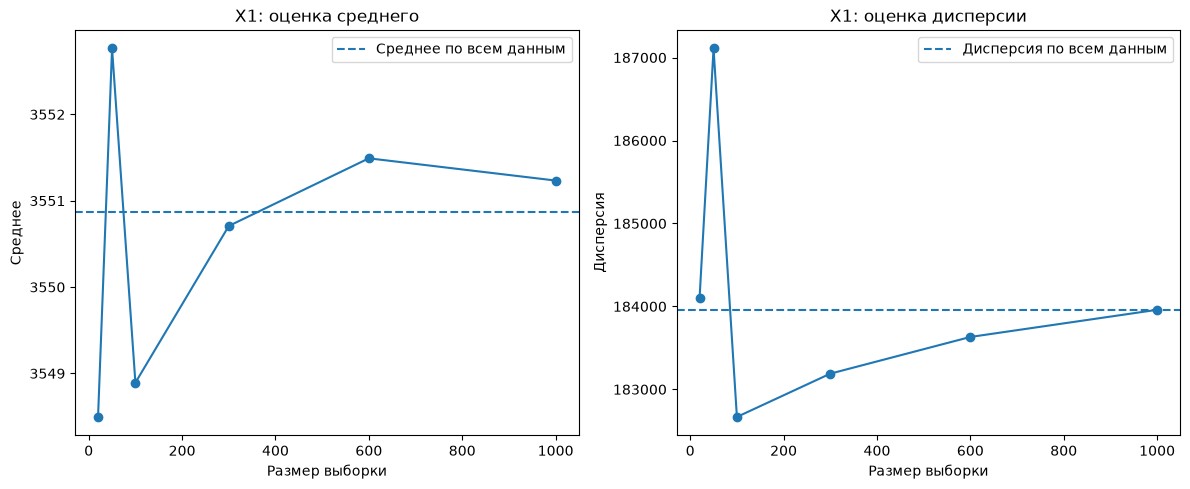

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Среднее
axes[0].plot(
    summary.index,
    summary["mean_estimate"],
    marker="o"
)
axes[0].axhline(
    true_mean,
    linestyle="--",
    label="Среднее по всем данным"
)
axes[0].set_title("X1: оценка среднего")
axes[0].set_xlabel("Размер выборки")
axes[0].set_ylabel("Среднее")
axes[0].legend()

# Дисперсия
axes[1].plot(
    summary.index,
    summary["variance_estimate"],
    marker="o"
)
axes[1].axhline(
    true_variance,
    linestyle="--",
    label="Дисперсия по всем данным"
)
axes[1].set_title("X1: оценка дисперсии")
axes[1].set_xlabel("Размер выборки")
axes[1].set_ylabel("Дисперсия")
axes[1].legend()

plt.tight_layout()
plt.show()

### Стандартизация

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

data["Z1"] = scaler.fit_transform(
    data[["X1"]]
)

print(data[["X1", "Z1"]].describe().round(3))

             X1        Z1
count  1960.000  1960.000
mean   3550.865     0.000
std     428.902     1.000
min    2439.000    -2.593
25%    3247.000    -0.709
50%    3556.000     0.012
75%    3862.000     0.726
max    4857.000     3.046


#### Математическая база распределения и его особенности

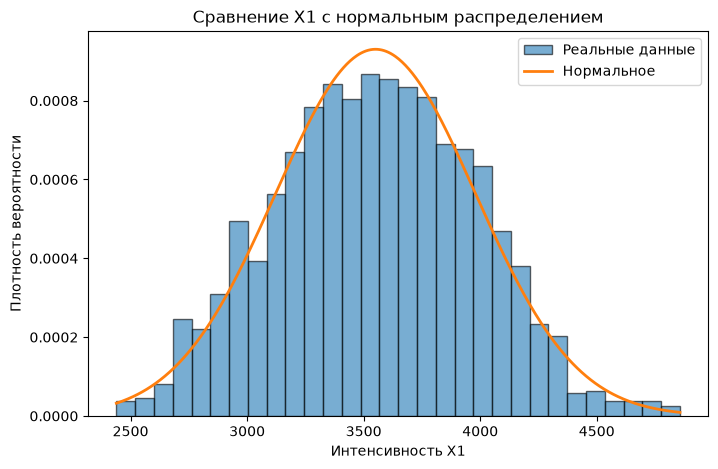

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

X1 = data["X1"].dropna()

mu = X1.mean()
sigma = X1.std(ddof=0)

x = np.linspace(X1.min(), X1.max(), 500)
y = norm.pdf(x, mu, sigma)

plt.figure(figsize=(8, 5))

plt.hist(
    X1,
    bins=30,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Реальные данные"
)

plt.plot(
    x,
    y,
    linewidth=2,
    label="Нормальное"
)

plt.title("Сравнение X1 с нормальным распределением")
plt.xlabel("Интенсивность X1")
plt.ylabel("Плотность вероятности")
plt.legend()
plt.show()

#### Проверка гипотезы о нормальности с помощью статистического критерия

In [27]:
from scipy.stats import shapiro

X1 = data["X1"].dropna()

sample_test = X1.sample(n=500, random_state=42)

statistic, p_value = shapiro(sample_test)

alpha = 0.05

print("Гипотеза 1: нормальность распределения X1")
print(f"Статистика Шапиро - Уилка: {statistic:.4f}")
print(f"p-value: {p_value:.6g}")

if p_value < alpha:
    print("Решение: отвергаем H0.")
    print("Есть статистические свидетельства против нормальности.")
else:
    print("Решение: нет оснований отвергнуть H0.")
    print("Данных недостаточно, чтобы заключить, что распределение ненормальное.")

Гипотеза 1: нормальность распределения X1
Статистика Шапиро - Уилка: 0.9945
p-value: 0.0710418
Решение: нет оснований отвергнуть H0.
Данных недостаточно, чтобы заключить, что распределение ненормальное.


In [28]:

from scipy.stats import pearsonr

# Выбираем два столбца и удаляем строки с пропущенными значениями
paired = data[["X2", "X3"]].dropna()

# Проверяем линейную корреляцию Пирсона
r, p_value = pearsonr(paired["X2"], paired["X3"])

alpha = 0.05

print("Гипотеза 2: линейная связь между X2 и X3")
print(f"Число наблюдений: {len(paired)}")
print(f"Коэффициент корреляции Пирсона: {r:.4f}")
print(f"p-value: {p_value:.6g}")

if p_value < alpha:
    print("Решение: отвергаем H0.")
    print("Линейная связь статистически значима.")
else:
    print("Решение: нет оснований отвергнуть H0.")
    print("Статистически значимая линейная связь не установлена.")


Гипотеза 2: линейная связь между X2 и X3
Число наблюдений: 1960
Коэффициент корреляции Пирсона: 0.9629
p-value: 0
Решение: отвергаем H0.
Линейная связь статистически значима.


### Independence & Estimations

In [18]:
print("Корреляция Пирсона:")
print(data[["X1", "X2", "X3"]].corr().round(3))

Корреляция Пирсона:
       X1     X2     X3
X1  1.000  0.885  0.877
X2  0.885  1.000  0.963
X3  0.877  0.963  1.000


In [19]:
spearman_corr = data[["X1", "X2", "X3"]].corr(method="spearman")

print("\nКорреляция Спирмена:")
print(spearman_corr.round(3))


Корреляция Спирмена:
       X1     X2     X3
X1  1.000  0.891  0.885
X2  0.891  1.000  0.965
X3  0.885  0.965  1.000


In [20]:
sugar_columns = [
    "Sucrose [ul]",
    "Fructose [ul]",
    "Maltose [ul]",
    "Glucose [ul]",
    "Water [ul]"
]

variables = ["X1", "X2", "X3"]

# Средняя интенсивность для каждого состава
composition_means = data.groupby(
    sugar_columns
)[variables].transform("mean")

# Отклонения каждого измерения от среднего своего состава
residuals = data[variables] - composition_means

print("Корреляция отклонений от среднего состава:")
print(residuals.corr().round(3))

print("\nСтандартные отклонения исходных интенсивностей:")
print(data[variables].std().round(2))

print("\nСтандартные отклонения отклонений внутри состава:")
print(residuals.std().round(2))


Корреляция отклонений от среднего состава:
       X1     X2     X3
X1  1.000  0.077  0.050
X2  0.077  1.000  0.068
X3  0.050  0.068  1.000

Стандартные отклонения исходных интенсивностей:
X1    428.90
X2    148.83
X3    233.30
dtype: float64

Стандартные отклонения отклонений внутри состава:
X1    46.05
X2    26.50
X3    35.56
dtype: float64


In [ ]:
Определим для величины 1 состоятельность оценок

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X1 = data["X1"]

# Характеристики всех 1960 измерений - ориентиры
true_mean = X1.mean()
true_variance = X1.var(ddof=1)

print(f"Среднее по всем данным: {true_mean:.2f}")
print(f"Дисперсия по всем данным: {true_variance:.2f}")

# Размеры выборок
sample_sizes = [20, 50, 100, 300, 600, 1000]
n_repeats = 500

rng = np.random.default_rng(42)
results = []

# Многократный случайный отбор без возвращения
for n in sample_sizes:
    for _ in range(n_repeats):
        sample = X1.sample(
            n=n,
            replace=False,
            random_state=int(rng.integers(0, 2**31))
        )

        results.append({
            "n": n,
            "mean": sample.mean(),
            "variance": sample.var(ddof=1)
        })

results = pd.DataFrame(results)

summary = results.groupby("n").agg(
    mean_estimate=("mean", "mean"),
    mean_sd=("mean", "std"),
    variance_estimate=("variance", "mean"),
    variance_sd=("variance", "std")
)

print("\nРезультаты:")
print(summary.round(2))

Среднее по всем данным: 3550.86
Дисперсия по всем данным: 183956.79

Результаты:
      mean_estimate  mean_sd  variance_estimate  variance_sd
n                                                           
20          3548.50    93.33          184096.51     54367.38
50          3552.76    60.33          187110.21     33687.18
100         3548.89    40.66          182667.17     23053.28
300         3550.71    21.87          183189.03     12322.17
600         3551.49    15.28          183631.52      8576.39
1000        3551.23     9.43          183958.95      4966.56


In [23]:
# Размеры выборок
sample_sizes = [20, 50, 100, 300, 600, 1000]
n_repeats = 500

results_with = []

# Многократный случайный отбор с возвращением
for n in sample_sizes:
    for _ in range(n_repeats):
        sample = X1.sample(
            n=n,
            replace=True,
            random_state=int(rng.integers(0, 2**31))
        )

        results_with.append({
            "n": n,
            "mean": sample.mean(),
            "variance": sample.var(ddof=1)
        })

results_with = pd.DataFrame(results_with)

# Сводная таблица
summary_with = results_with.groupby("n").agg(
    mean_estimate=("mean", "mean"),
    mean_sd=("mean", "std"),
    variance_estimate=("variance", "mean"),
    variance_sd=("variance", "std")
)

print("Результаты с возвращением:")
print(summary_with.round(2))

Результаты с возвращением:
      mean_estimate  mean_sd  variance_estimate  variance_sd
n                                                           
20          3559.05   100.09          183365.42     53865.43
50          3549.10    62.43          183382.61     32417.50
100         3548.73    43.20          183797.94     23629.73
300         3551.04    24.38          184974.67     13934.51
600         3549.12    17.34          183456.12      9654.61
1000        3550.52    14.28          184008.01      7476.21


## Random Variable 03-X3 (интенсивность при 1399,34 см⁻¹)

### Description

В качестве третьей величины взяли интенсивность рамановского сигнала при 1399,34 см⁻¹. Это рамановский сдвиг. В датасете 1960 спектров: 245 составов смесей сахаров и воды, каждый измеряли по 8 раз.

Даже для одного состава интенсивность может немного меняться из-за шума детектора, фона и условий измерения. Поэтому результат отдельного измерения нельзя точно предсказать только по составу раствора, и X3 рассматриваем как случайную величину.

При этом нужно различать разброс между составами и между повторами одного состава. Потом будем смотреть, какой из них сильнее влияет на сигнал.

Источник: [Raman_Sugars](https://github.com/Alvaro-FG/Raman_Sugars). Интенсивность дана в отсчётах прибора, а рамановский сдвиг — в см⁻¹.


### EDA и распределение X3

Сначала посчитаем основные статистики X3: среднее, медиану, дисперсию, стандартное отклонение, квартили, асимметрию и эксцесс. Они помогут оценить уровень сигнала, его разброс и форму распределения. Заодно проверим число составов и различия между повторными измерениями.


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# В исходном ноутбуке data уже собран из metadata и спектров.
assert "X3" in data.columns, "Сначала выполните ячейки загрузки данных"
x3 = pd.to_numeric(data["X3"], errors="coerce").dropna()
N = len(x3)

sugar_cols_x3 = ["Sucrose [ul]", "Fructose [ul]", "Maltose [ul]",
                 "Glucose [ul]", "Water [ul]"]
assert all(col in data for col in sugar_cols_x3)

summ_x3 = pd.Series({
    "Число наблюдений": N,
    "Пропусков": data["X3"].isna().sum(),
    "Среднее": x3.mean(),
    "Медиана": x3.median(),
    "Стандартное отклонение (ddof=1)": x3.std(ddof=1),
    "Дисперсия (ddof=1)": x3.var(ddof=1),
    "Минимум": x3.min(),
    "Q1": x3.quantile(0.25),
    "Q3": x3.quantile(0.75),
    "Максимум": x3.max(),
    "Коэффициент вариации, %": 100*x3.std(ddof=1)/x3.mean(),
    "Асимметрия": x3.skew(),
    "Избыточный эксцесс": x3.kurt()
})
display(summ_x3.to_frame(name="X3, интенсивность"))

group_sizes_x3 = data.groupby(sugar_cols_x3, dropna=False).size()
print(f"Число уникальных составов: {len(group_sizes_x3)}")
print("Число измерений на один состав:", group_sizes_x3.value_counts().to_dict())
within_sd_groups3 = data.groupby(sugar_cols_x3, dropna=False)["X3"].std(ddof=1)
print(f"Составов с ненулевым разбросом в повторах: {(within_sd_groups3 > 0).sum()} из {len(within_sd_groups3)}")
print(f"Медиана SD внутри одного состава: {within_sd_groups3.median():.2f}")
print("Точка спектра: 1399.34 см⁻¹ (из исходной таблицы wavenumbers)")

,"X3, интенсивность"
Число наблюдений,1960.000000
Пропусков,0.000000
Среднее,1534.551020
Медиана,1533.000000
Стандартное отклонение (ddof=1),233.297892
Дисперсия (ddof=1),54427.906533
Минимум,975.000000
Q1,1362.750000
Q3,1698.250000
Максимум,2544.000000


Число уникальных составов: 245
Число измерений на один состав: {8: 245}
Составов с ненулевым разбросом в повторах: 245 из 245
Медиана SD внутри одного состава: 25.05
Точка спектра: 1399.34 см⁻¹ (из исходной таблицы wavenumbers)


Среднее X3 составляет примерно 1534,55, медиана 1533. Они почти совпадают, поэтому заметного смещения центра распределения не видно. Стандартное отклонение около 233,30, а значения лежат в диапазоне 975–2544.

Разброс довольно большой, но это не обязательно шум: мы сравниваем разные составы растворов. Поэтому дальше отдельно рассмотрим повторы одного состава.


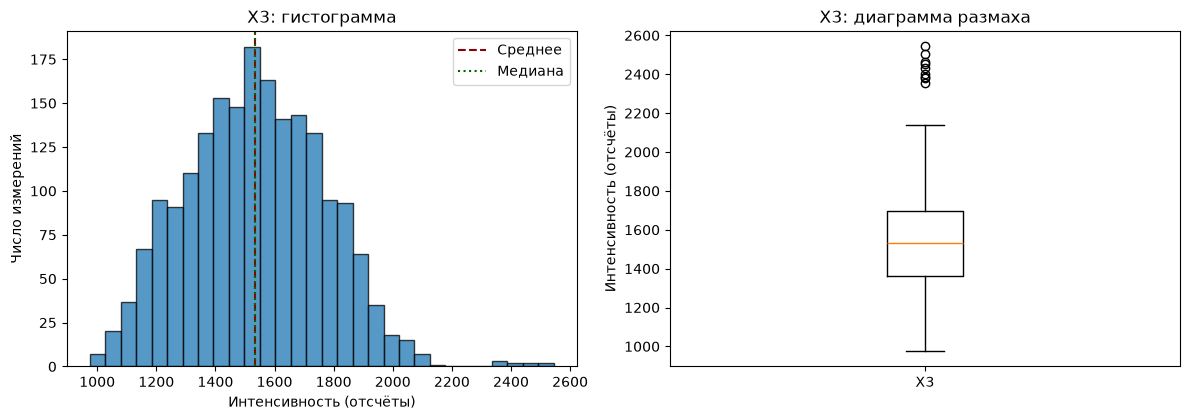

Наблюдений за границами 1.5×IQR: 9 из 1960 
Это только правило поиска необычных значений, не основание автоматически удалять их.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].hist(x3, bins=30, edgecolor="black", alpha=0.75)
axes[0].axvline(x3.mean(), color="darkred", linestyle="--", label="Среднее")
axes[0].axvline(x3.median(), color="darkgreen", linestyle=":", label="Медиана")
axes[0].set(title="X3: гистограмма", xlabel="Интенсивность (отсчёты)",
            ylabel="Число измерений")
axes[0].legend()
axes[1].boxplot(x3, orientation="vertical")
axes[1].set(title="X3: диаграмма размаха", ylabel="Интенсивность (отсчёты)")
axes[1].set_xticks([1], ["X3"])
plt.tight_layout()
plt.show()

q1, q3 = x3.quantile([0.25, 0.75])
iqr = q3-q1
outliers = (x3 < q1-1.5*iqr) | (x3 > q3+1.5*iqr)
print(f"Наблюдений за границами 1.5×IQR: {int(outliers.sum())} из {N} ")
print("Это только правило поиска необычных значений, не основание автоматически удалять их.")

На гистограмме посмотрим, какие интенсивности встречаются чаще и насколько распределение симметрично. На диаграмме размаха можно заметить слишком высокие/низкие значения.

Такие значения не убираем, тк они могут быть связаны с составом раствора. Близость среднего к медиане не доказывает нормальность распределения.


#### Математическая база распределения и его особенности

Если много раз измерять один и тот же раствор, интенсивности будут колебаться около некоторого среднего. При действии большого числа небольших случайных факторов их распределение может быть близко к нормальному. Для нормального закона среднее задаёт центр, а стандартное отклонение-ширину распределения.

Но у нас 245 разных составов, поэтому общий набор фактически объединяет распределения нескольких групп. Даже если для каждого состава шум примерно нормальный, все 1960 значений вместе не обязаны иметь нормальное распределение. Проверим это по графикам и статистическому критерию.

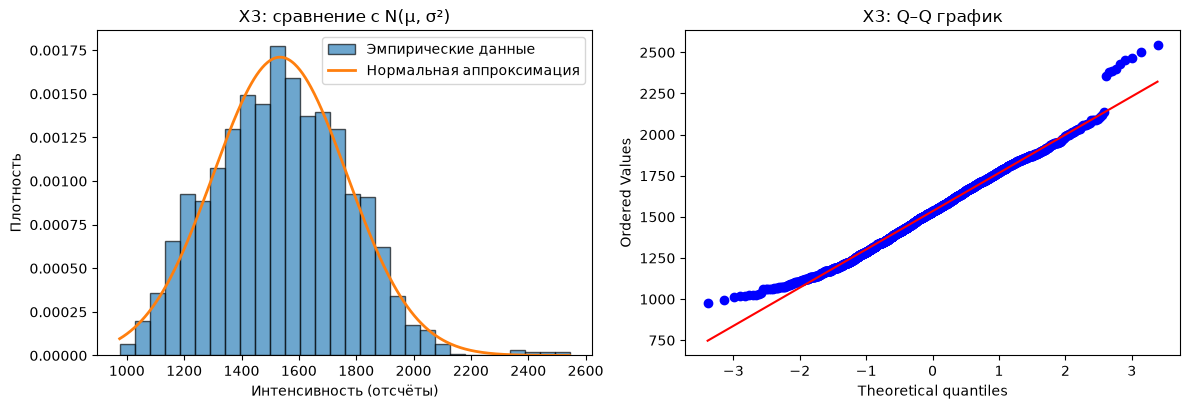

Нормальная модель, подобранная по всей выборке: μ=1534.55, σ=233.24


In [9]:
mu3 = x3.mean()
sigma3 = x3.std(ddof=0)
xgrid = np.linspace(x3.min(), x3.max(), 500)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(x3, bins=30, density=True, edgecolor="black", alpha=0.65,
             label="Эмпирические данные")
axes[0].plot(xgrid, stats.norm.pdf(xgrid, loc=mu3, scale=sigma3),
             linewidth=2, label="Нормальная аппроксимация")
axes[0].set(title="X3: сравнение с N(μ, σ²)",
            xlabel="Интенсивность (отсчёты)", ylabel="Плотность")
axes[0].legend()

stats.probplot(x3, dist="norm", plot=axes[1])
axes[1].set_title("X3: Q–Q график")
plt.tight_layout()
plt.show()

print(f"Нормальная модель, подобранная по всей выборке: μ={mu3:.2f}, σ={sigma3:.2f}")

На первом графике сравним гистограмму X3 с нормальной кривой, подобранной по среднему и стандартному отклонению. На Q–Q графике точки при близости к нормальному распределению должны лежать примерно вдоль прямой.

Если видим заметные отклонения, нормальная модель описывает данные не очень хорошо. Но даже похожий график ещё ничего не говорит о независимости повторных измерений.


#### Проверка гипотезы о нормальности

Для проверки используем критерий Шапиро–Уилка, как и при анализе X1.
H₀:распределение X3 нормальное. 
H₁:распределение X3 отличается от нормального.

Уровень значимости 0,05. Возьмём случайную подвыборку из 500 измерений. Если p-value меньше 0,05, отвергаем H₀; иначе оснований отвергать её нет.

Нужно учитывать, что в данных есть повторы одних и тех же составов.


In [11]:
shapiro_x3 = x3.sample(n=min(500, N), random_state=42)
w3, p_norm3 = stats.shapiro(shapiro_x3)
print(f"Шапиро–Уилк: W={w3:.5f}; p={p_norm3:.6g}; α=0.05")
print("Отвергаем H0 о нормальности" if p_norm3 < 0.05
      else "Недостаточно оснований отвергнуть H0 (это не доказывает нормальность)")

Шапиро–Уилк: W=0.99064; p=0.00291453; α=0.05
Отвергаем H0 о нормальности


По полученному p-value решим, отвергать ли нормальность X3. Если p-value не меньше 0,05, это не доказывает нормальное распределение. это означает, что тест не выявил достаточных оснований его отвергнуть.

Также проверка относится ко всему набору разных составов, а не отдельно к шуму измерений одного раствора.


### Стандартизация X3

Теперь стандартизируем X3: вычтем из каждого значения среднее и разделим на стандартное отклонение. Так увидим, на сколько стандартных отклонений конкретный сигнал выше или ниже среднего.

После преобразования среднее должно быть примерно 0, а стандартное отклонение примерно 1, что удобно для сравнения X3 с X1 и X2. При этом форма распределения не меняется и нормальным оно автоматически не становится.


              X3         Z3
count  1960.0000  1960.0000
mean   1534.5510    -0.0000
std     233.2979     1.0003
min     975.0000    -2.3991
25%    1362.7500    -0.7366
50%    1533.0000    -0.0066
75%    1698.2500     0.7019
max    2544.0000     4.3280
Контроль: E[Z3]=-4.355e-16; SD₀[Z3]=1.000000


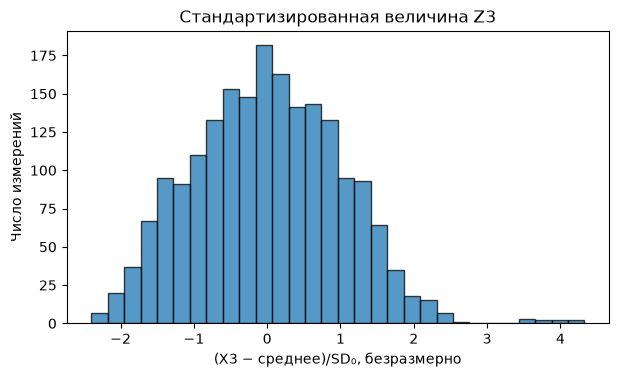

In [12]:
# Стандартизируем исходную таблицу без потери связей с составом раствора.
scaling_mean3 = data["X3"].mean()
scaling_sd3 = data["X3"].std(ddof=0)
assert scaling_sd3 > 0

data["Z3"] = (data["X3"]-scaling_mean3)/scaling_sd3
print(data[["X3", "Z3"]].describe().round(4))
print(f"Контроль: E[Z3]={data['Z3'].mean():.3e}; SD₀[Z3]={data['Z3'].std(ddof=0):.6f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(data["Z3"].dropna(), bins=30, edgecolor="black", alpha=0.75)
ax.set(title="Стандартизированная величина Z3",
       xlabel="(X3 − среднее)/SD₀, безразмерно", ylabel="Число измерений")
plt.show()

Проверим, что после стандартизации среднее действительно близко к нулю, а стандартное отклонение — к единице. Положительные значения означают интенсивность выше средней, отрицательные — ниже. Сам порядок наблюдений сохраняется.


### Independence & Estimations (исследование зависимости)

Проверим связь X3 с X1 и X2 с помощью корреляций Пирсона и Спирмена. Эти величины получены из одного спектра, поэтому вполне могут зависеть друг от друга.

Но высокая корреляция может появиться просто потому, что разные составы по-разному влияют на обе интенсивности. Поэтому сначала сравним исходные значения, а затем отклонения от среднего внутри каждого состава. Так сможем отделить влияние состава от изменений между повторными измерениями. Слабая корреляция при этом ещё не доказывает независимость.


Корреляция Пирсона исходных интенсивностей:


,X1,X2,X3
X1,1.0000,0.8852,0.8766
X2,0.8852,1.0000,0.9629
X3,0.8766,0.9629,1.0000


Корреляция Пирсона после вычитания средних по составу:


,X1,X2,X3
X1,1.0000,0.0773,0.0503
X2,0.0773,1.0000,0.0679
X3,0.0503,0.0679,1.0000


Корреляция Спирмена исходных интенсивностей:


,X1,X2,X3
X1,1.0000,0.8909,0.8853
X2,0.8909,1.0000,0.9653
X3,0.8853,0.9653,1.0000


X2 ↔ X3: r=0.9629, p=0 (тест нулевой линейной корреляции)
Доля разброса X3, объясняемая различиями средних составов, η²=0.9768
SD(X3)=233.30; SD(остатков)=35.56


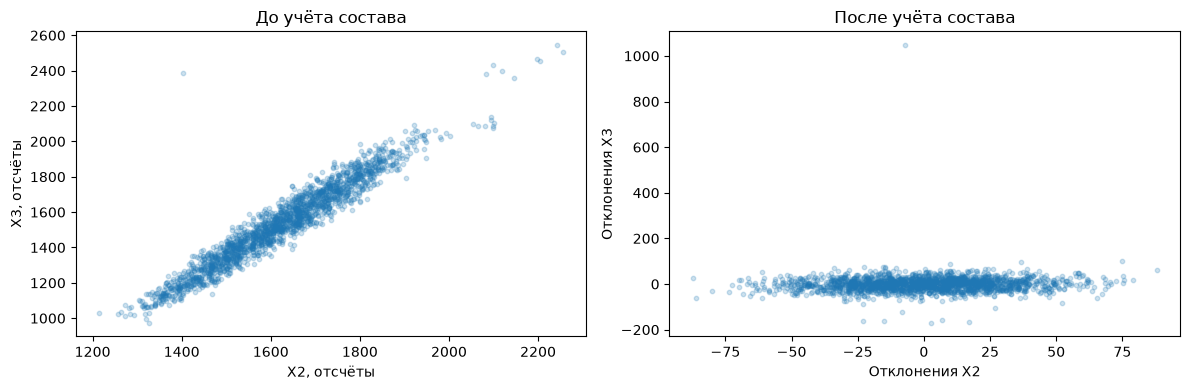

In [13]:
vars_x3 = ["X1", "X2", "X3"]
bycomp_x3 = data.groupby(sugar_cols_x3, dropna=False)[vars_x3]
centered_x3 = data[vars_x3] - bycomp_x3.transform("mean")

print("Корреляция Пирсона исходных интенсивностей:")
display(data[vars_x3].corr().round(4))
print("Корреляция Пирсона после вычитания средних по составу:")
display(centered_x3.corr().round(4))
print("Корреляция Спирмена исходных интенсивностей:")
display(data[vars_x3].corr(method="spearman").round(4))

r23, p23 = stats.pearsonr(data["X2"], data["X3"])
print(f"X2 ↔ X3: r={r23:.4f}, p={p23:.3g} (тест нулевой линейной корреляции)")

ss_total3 = ((data["X3"] - data["X3"].mean())**2).sum()
ss_within3 = centered_x3["X3"].pow(2).sum()
eta2_x3 = 1 - ss_within3 / ss_total3
print(f"Доля разброса X3, объясняемая различиями средних составов, η²={eta2_x3:.4f}")
print(f"SD(X3)={data['X3'].std(ddof=1):.2f}; SD(остатков)={centered_x3['X3'].std(ddof=1):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(data["X2"], data["X3"], alpha=0.22, s=10)
axes[0].set(xlabel="X2, отсчёты", ylabel="X3, отсчёты", title="До учёта состава")
axes[1].scatter(centered_x3["X2"], centered_x3["X3"], alpha=0.22, s=10)
axes[1].set(xlabel="Отклонения X2", ylabel="Отклонения X3", title="После учёта состава")
plt.tight_layout()
plt.show()

Для всех измерений корреляция X2 и X3 получилась высокой: r ≈ 0,963. После вычитания средних по каждому составу она снизилась до r ≈ 0,068. Стандартное отклонение X3 также уменьшилось примерно с 233,30 до 35,56.

Значит, основная часть разброса и связи между интенсивностями объясняется различиями составов, а не колебаниями между повторами. Но полную независимость X2 и X3 этим не доказали.


### Генеральная совокупность и выборка

В рамках задания будем считать все 1960 измерений конечной генеральной совокупностью. Проверим, насколько хорошо часть данных отражает весь набор.

Возьмём по 490 измерений двумя способами: случайно без возвращения и по 2 измерения от каждого из 245 составов. Второй же способ гарантирует, что ни один состав не потеряется.

Сравним среднее, медиану, дисперсию и гистограммы с полным датасетом. Посмотрим, какой способ даёт более близкие оценки в нашем эксперименте.


,N,mean,median,std,variance,"Ошибка среднего, %","Ошибка дисперсии, %"
Генеральная (1960),1960.0,1534.551,1533.0,233.298,54427.907,0.000,0.000
Простая выборка,490.0,1525.535,1525.0,231.641,53657.701,-0.588,-1.415
Стратифицированная,490.0,1532.749,1534.5,234.899,55177.755,-0.117,1.378


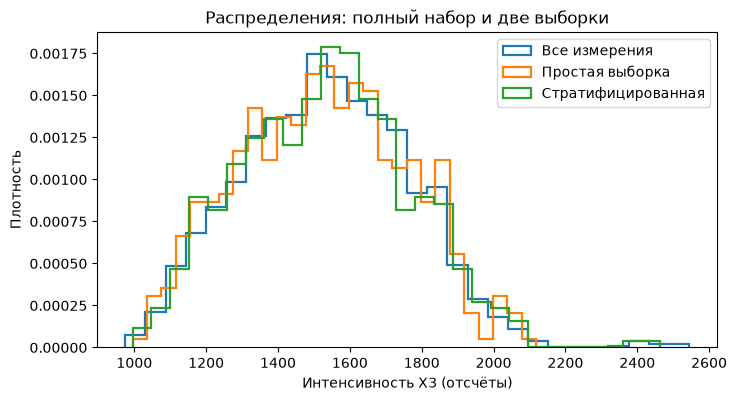

In [14]:
counts_x3 = data.groupby(sugar_cols_x3, dropna=False).size()
assert (counts_x3 >= 2).all(), "Для 2 измерений на состав необходимы ≥2 повтора"

n_take3 = 2*len(counts_x3)
srs3 = data.sample(n=n_take3, replace=False, random_state=2026)
strat3 = (data.groupby(sugar_cols_x3, group_keys=False, sort=False, dropna=False)
          .sample(n=2, replace=False, random_state=2026))

def x3_sample_stats(s):
    y = s["X3"].dropna()
    return pd.Series({"N": len(y), "mean": y.mean(), "median": y.median(),
                      "std": y.std(ddof=1), "variance": y.var(ddof=1)})

population3 = x3_sample_stats(data)
comparison3 = pd.DataFrame({
    "Генеральная (1960)": population3,
    "Простая выборка": x3_sample_stats(srs3),
    "Стратифицированная": x3_sample_stats(strat3)
}).T
comparison3["Ошибка среднего, %"] = (100*(comparison3["mean"]-population3["mean"])
                                    /population3["mean"])
comparison3["Ошибка дисперсии, %"] = (100*(comparison3["variance"]-population3["variance"])
                                      /population3["variance"])
display(comparison3.round(3))

fig, ax=plt.subplots(figsize=(8, 4.1))
for y, name in [(data["X3"],"Все измерения"),
                (srs3["X3"],"Простая выборка"),
                (strat3["X3"],"Стратифицированная")]:
    ax.hist(y, bins=28, density=True, histtype="step", linewidth=1.6,
            label=name)
ax.set(title="Распределения: полный набор и две выборки",
       xlabel="Интенсивность X3 (отсчёты)", ylabel="Плотность")
ax.legend()
plt.show()

Сравним характеристики двух выборок с полным набором. Особенно посмотрим на отклонения среднего и дисперсии: чем они меньше, тем точнее выборка отражает наши 1960 измерений.

По гистограммам дополнительно оценим сходство формы распределений. Но одна случайная выборка может оказаться удачнее другой, поэтому не будем делать общий вывод только по одному графику.


### Состоятельность оценок

Состоятельность означает, что с увеличением объёма выборки оценка должна приближаться к характеристике генеральной совокупности. Проверим это на среднем и дисперсии.

Будем брать выборки размером от 20 до 1500 измерений, повторяя отбор 400 раз для каждого размера. Сравним два случая:с возвращением (строка может попасть повторно) и без возвращения (каждую строку берём не более одного раза).

Ожидаем, что при увеличении выборки разброс оценок уменьшится, особенно при отборе без возвращения. Это эмпирическая проверка.


,Способ,n,Среднее оценок,SD средних,SD средних (теория),Средняя оценка дисперсии,SD оценок дисперсии
0,Без возвращения,20,1537.20,53.86,51.90,52298.84,17158.78
1,Без возвращения,50,1531.47,31.66,32.57,54916.87,11286.14
2,Без возвращения,100,1535.12,21.47,22.73,54504.47,7600.67
3,Без возвращения,300,1533.37,12.33,12.40,54295.55,4131.85
4,Без возвращения,600,1534.75,8.58,7.93,54146.98,2726.80
5,Без возвращения,1000,1534.65,5.03,5.16,54442.08,1799.78
6,Без возвращения,1500,1534.22,2.88,2.92,54435.08,1052.94
7,С возвращением,20,1530.08,48.58,52.15,53520.20,17906.79
8,С возвращением,50,1534.64,31.32,32.98,54353.70,11140.16
9,С возвращением,100,1533.78,22.31,23.32,54958.13,8203.34


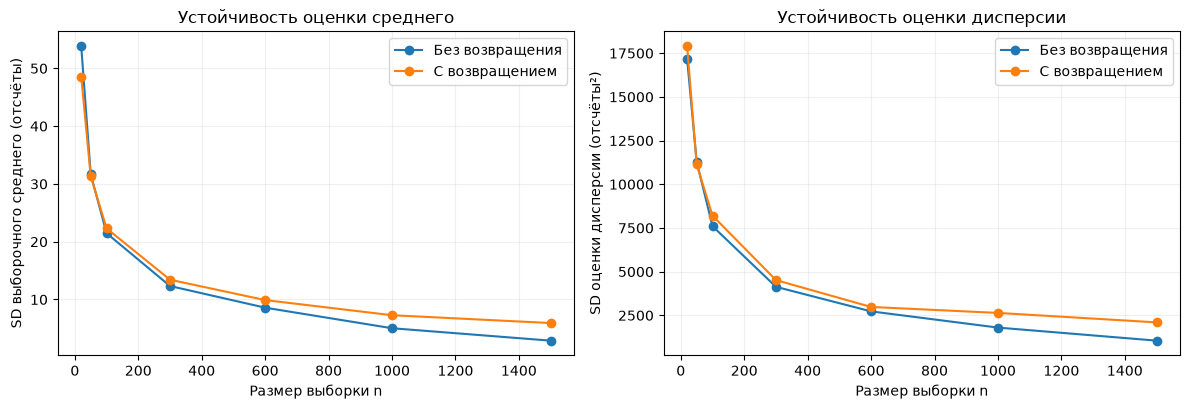

In [15]:
seed3 = np.random.default_rng(1400)
values3 = x3.to_numpy()
N3 = len(values3)
sizes3 = [20, 50, 100, 300, 600, 1000, 1500]
B3 = 400
sim_rows3 = []

for replace in (False, True):
    method = "С возвращением" if replace else "Без возвращения"
    for n in sizes3:
        means = np.empty(B3)
        variances = np.empty(B3)
        for b in range(B3):
            draw = seed3.choice(values3, size=n, replace=replace)
            means[b] = draw.mean()
            variances[b] = draw.var(ddof=1)
        theory_sd = (np.sqrt(values3.var(ddof=0)/n) if replace
                     else np.sqrt(values3.var(ddof=1)*(1-n/N3)/n))
        sim_rows3.append({"Способ": method, "n": n,
                          "Среднее оценок": means.mean(),
                          "SD средних": means.std(ddof=1),
                          "SD средних (теория)": theory_sd,
                          "Средняя оценка дисперсии": variances.mean(),
                          "SD оценок дисперсии": variances.std(ddof=1)})

sim3 = pd.DataFrame(sim_rows3)
display(sim3.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for method, subset in sim3.groupby("Способ"):
    axes[0].plot(subset["n"], subset["SD средних"], "o-", label=method)
    axes[1].plot(subset["n"], subset["SD оценок дисперсии"], "o-", label=method)
axes[0].set(title="Устойчивость оценки среднего", xlabel="Размер выборки n",
            ylabel="SD выборочного среднего (отсчёты)")
axes[1].set(title="Устойчивость оценки дисперсии", xlabel="Размер выборки n",
            ylabel="SD оценки дисперсии (отсчёты²)")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

На графиках посмотрим, как меняется разброс оценок среднего и дисперсии с увеличением числа наблюдений. Если линии в целом идут вниз, оценки становятся устойчивее.

Без возвращения разброс среднего обычно меньше, потому что измерения не повторяются. Окончательный вывод сделаем по полученным графикам и таблице, а не только по ожиданиям.


### Проверка статистической гипотезы о связи с составом раствора

Проверим, связан ли сигнал X3 с суммарным объёмом добавленных сахарных растворов. Это именно объём растворов, а не концентрация сахаров.

Сначала усредним X3 для каждого из 245 составов, чтобы не считать восемь повторов независимыми смесями. Затем найдём корреляцию Спирмена между средней интенсивностью и суммарным объёмом сахарных растворов.
H₀: монотонной связи нет. H₁: монотонная связь есть.

Уровень значимости 0,05. Даже если связь окажется значимой, это ещё не доказывает причинное влияние общего объёма: важны и соотношения конкретных сахаров.


Число разных составов: 245
Спирмен: rho=0.8736, p=5.6978e-78
При α=0.05 отвергаем H0: выявлена статистически значимая монотонная связь


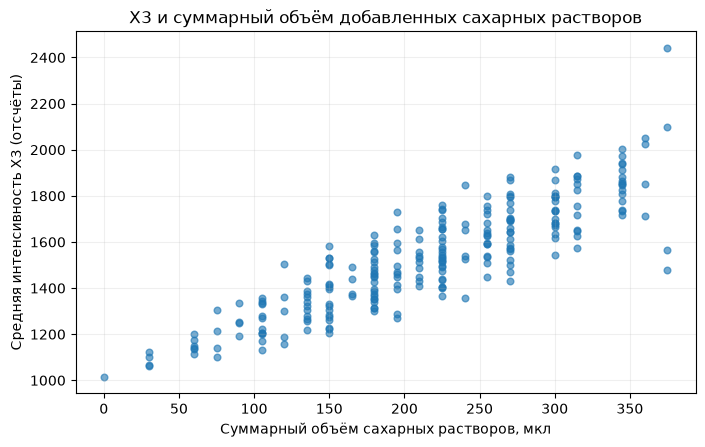

In [16]:
comp_means3 = (data.groupby(sugar_cols_x3, as_index=False, dropna=False)
               .agg(X3_mean=("X3", "mean"), n_measurements=("X3", "size")))
comp_means3["Total sugars [ul]"] = comp_means3[
    sugar_cols_x3[:-1]].sum(axis=1)

rho3, p_assoc3 = stats.spearmanr(comp_means3["Total sugars [ul]"],
                                 comp_means3["X3_mean"])
print(f"Число разных составов: {len(comp_means3)}")
print(f"Спирмен: rho={rho3:.4f}, p={p_assoc3:.6g}")
if p_assoc3 < 0.05:
    print("При α=0.05 отвергаем H0: выявлена статистически значимая монотонная связь")
else:
    print("При α=0.05 не отвергаем H0: значимая монотонная связь не установлена")

fig, ax = plt.subplots(figsize=(8, 4.7))
ax.scatter(comp_means3["Total sugars [ul]"], comp_means3["X3_mean"],
           s=23, alpha=0.62)
ax.set(title="X3 и суммарный объём добавленных сахарных растворов",
       xlabel="Суммарный объём сахарных растворов, мкл",
       ylabel="Средняя интенсивность X3 (отсчёты)")
ax.grid(alpha=0.2)
plt.show()

Посмотрим на коэффициент Спирмена и p-value. Коэффициент покажет направление и выраженность монотонной связи, а p-value на то, есть ли основания отвергнуть H₀.

На диаграмме проверим, меняется ли средняя интенсивность вместе с суммарным объёмом сахарных растворов. Если связи нет, то скорее всего важнее соотношение отдельных сахаров, а не их общий объём.


### вывод по третьей величине

Ниже код автоматически соберёт основные результаты X3: среднее, разброс, корреляции и p-value. Итог сформулируем по реально полученным значениям.

Главное при интерпретации- это различать изменение сигнала из-за состава смеси и разброс повторных измерений. Иначе можно ошибочно принять влияние состава за шум прибора.


In [18]:
# Численные выводы формируются по реальным значениям при запуске ноутбука,
# без заранее придуманных p-value, корреляций и оценок.
method_table3 = sim3.set_index(["Способ", "n"])
ss20_no3 = method_table3.loc[("Без возвращения",20), "SD средних"]
ss1500_no3 = method_table3.loc[("Без возвращения",1500), "SD средних"]
ss20_yes3 = method_table3.loc[("С возвращением",20), "SD средних"]
ss1500_yes3 = method_table3.loc[("С возвращением",1500), "SD средних"]
association3 = ("статистически значимую" if p_assoc3 < 0.05
                else "статистически не подтверждённую")
norm3 = ("гипотеза о нормальности отвергнута" if p_norm3 < 0.05
         else "оснований отвергнуть гипотезу о нормальности не найдено")

conclusion3 = f"""
В данной части проанализирована случайная величина X3 — интенсивность при 1399,34 см⁻¹
({N3} измерений, {len(comp_means3)} составов по {int(group_sizes_x3.iloc[0])} повторов).
Средняя интенсивность составляет {x3.mean():.2f}, стандартное отклонение
{x3.std(ddof=1):.2f} отсчёта. При проверке Шапиро–Уилка {norm3}
(p={p_norm3:.4g}); этот тест имеет ограничения из-за сгруппированных измерений.

Связь X3 с X2 в исходных данных сильная (Пирсон r={r23:.3f}),
но после вычитания средних каждого состава остаточная корреляция составляет
r={centered_x3['X2'].corr(centered_x3['X3']):.3f}. По суммам квадратов
{100*eta2_x3:.1f}% наблюдаемого разброса X3 приходится на
различия средних между составами. Поэтому описывать все измерения одной
«погрешностью прибора» некорректно.

У 245 средних интенсивностей для отдельных составов проверена связь с суммарным
объёмом добавленных сахарных растворов: ρ={rho3:.3f}, p={p_assoc3:.4g}.
Получена {association3} ранговую связь при α=0.05.

В эксперименте с увеличением n от 20 до 1500 разброс оценок среднего
без возвращения меняется с {ss20_no3:.2f} до {ss1500_no3:.2f}, а с
возвращением-с {ss20_yes3:.2f} до {ss1500_yes3:.2f}.
Снижение разброса согласуется с состоятельностью оценки среднего в модели
случайного отбора; дисперсия анализируется аналогично по таблице выше.
Выборки из 490 спектров двух типов сопоставлены с полным набором
по среднему, медиане и дисперсии.

Ограничение: данная работа оценивает статистическую структуру записанного набора;
для утверждений о физических причинах конкретной полосы и переносе результатов
на новые партии растворов нужны отдельные спектральные и экспериментальные проверки.
"""
display(Markdown(conclusion3))


В данной части проанализирована случайная величина X3 — интенсивность при 1399,34 см⁻¹
(1960 измерений, 245 составов по 8 повторов).
Средняя интенсивность составляет 1534.55, стандартное отклонение
233.30 отсчёта. При проверке Шапиро–Уилка гипотеза о нормальности отвергнута
(p=0.002915); этот тест имеет ограничения из-за сгруппированных измерений.

Связь X3 с X2 в исходных данных сильная (Пирсон r=0.963),
но после вычитания средних каждого состава остаточная корреляция составляет
r=0.068. По суммам квадратов
97.7% наблюдаемого разброса X3 приходится на
различия средних между составами. Поэтому описывать все измерения одной
«погрешностью прибора» некорректно.

У 245 средних интенсивностей для отдельных составов проверена связь с суммарным
объёмом добавленных сахарных растворов: ρ=0.874, p=5.698e-78.
Получена статистически значимую ранговую связь при α=0.05.

В эксперименте с увеличением n от 20 до 1500 разброс оценок среднего
без возвращения меняется с 53.86 до 2.88, а с
возвращением-с 48.58 до 5.92.
Снижение разброса согласуется с состоятельностью оценки среднего в модели
случайного отбора; дисперсия анализируется аналогично по таблице выше.
Выборки из 490 спектров двух типов сопоставлены с полным набором
по среднему, медиане и дисперсии.

Ограничение: данная работа оценивает статистическую структуру записанного набора;
для утверждений о физических причинах конкретной полосы и переносе результатов
на новые партии растворов нужны отдельные спектральные и экспериментальные проверки.
